# 6D Object Pose Estimation with GDRNPP and OpenVINO

[GDRNPP](https://github.com/shanice-l/gdrnpp_bop2022) (Geometry-Guided Direct Regression Network++, [paper](https://arxiv.org/abs/2102.12145)) estimates the 6D pose, meaning the 3D rotation and translation, of known objects from a single RGB image. It won most awards of the [BOP Challenge 2022](https://bop.felk.cvut.cz/challenges/bop-challenge-2022/). The pipeline has two stages: a YOLOX detector finds each object, then the GDRN network predicts dense 2D-3D correspondences for every detection and recovers its pose.

This tutorial uses the models trained on the Linemod-Occluded (LM-O) dataset and:

* downloads the released checkpoints and one LM-O test image,
* converts the YOLOX detector and the GDRN pose network to OpenVINO IR and verifies the conversion,
* runs the full pipeline on the selected device, such as CPU, GPU or NPU.

#### Table of contents:

- [Prerequisites](#Prerequisites)
- [Download checkpoints and sample data](#Download-checkpoints-and-sample-data)
- [Load the PyTorch models](#Load-the-PyTorch-models)
    - [Run the PyTorch models](#Run-the-PyTorch-models)
- [Convert the models to OpenVINO IR](#Convert-the-models-to-OpenVINO-IR)
- [Run OpenVINO inference](#Run-OpenVINO-inference)
    - [Select inference device](#Select-inference-device)
    - [Estimate object poses](#Estimate-object-poses)
    - [Verify the conversion](#Verify-the-conversion)
- [Clean up](#Clean-up)

### Installation Instructions

This is a self-contained example that relies solely on its own code.

We recommend  running the notebook in a virtual environment. You only need a Jupyter server to start.
For details, please refer to [Installation Guide](https://github.com/openvinotoolkit/openvino_notebooks/blob/latest/README.md#-installation-guide).

<img referrerpolicy="no-referrer-when-downgrade" src="https://static.scarf.sh/a.png?x-pxid=5b5a4db0-7875-4bfb-bdbd-01698b5b1a77&file=notebooks/gdrnpp-full-pipeline/gdrnpp-full-pipeline.ipynb" />

## Prerequisites
[back to top ⬆️](#Table-of-contents:)

In [1]:
import urllib.request
from pathlib import Path

helper_files = ["notebook_utils.py"]
repo_utils = Path("../../utils")
in_repo = (repo_utils / "notebook_utils.py").is_file()
if in_repo:
    helper_contents = {helper_file: (repo_utils / helper_file).read_bytes() for helper_file in helper_files}
else:
    try:
        helper_contents = {}
        for helper_file in helper_files:
            url = f"https://raw.githubusercontent.com/openvinotoolkit/openvino_notebooks/latest/utils/{helper_file}"
            with urllib.request.urlopen(url, timeout=10) as response:
                helper_contents[helper_file] = response.read()
    except OSError as error:
        if any(not Path(helper_file).is_file() for helper_file in helper_files):
            raise
        print(f"Could not update helper files, using the existing copies: {error}")
        helper_contents = {}

for helper_file, content in helper_contents.items():
    Path(helper_file).write_bytes(content)

from notebook_utils import setup_notebook_venv

# Requirements installed below go to a notebook-specific virtual environment in the `.venv` folder
setup_notebook_venv()

In [ ]:
%pip install -q "openvino>=2026.1.0" "torch>=2.8" --extra-index-url https://download.pytorch.org/whl/cpu
%pip install -q opencv-python "matplotlib>=3.4" ipywidgets tqdm requests remotezip

from pathlib import Path

# Read more about telemetry collection at https://github.com/openvinotoolkit/openvino_notebooks?tab=readme-ov-file#-telemetry
from notebook_utils import collect_telemetry

collect_telemetry("gdrnpp-full-pipeline.ipynb")

The network definitions, pre- and post-processing, and drawing utilities live in `gdrnpp_helper.py` next to this notebook. They use only PyTorch, NumPy and OpenCV, so no GDRNPP checkout, `mmcv` or `detectron2` is needed.

In [2]:
import json
import time

import cv2
import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import openvino as ov
import torch

import gdrnpp_helper as gdrnpp

MODEL_DIR = Path("model")
DATA_DIR = Path("data")
YOLOX_IR_PATH = MODEL_DIR / "yolox.xml"
GDRN_IR_PATH = MODEL_DIR / "gdrn.xml"

# GDRN class index i corresponds to LM-O object id LMO_OBJECT_IDS[i]
LMO_OBJECT_IDS = [1, 5, 6, 8, 9, 10, 11, 12]
LMO_OBJECT_NAMES = ["ape", "can", "cat", "driller", "duck", "eggbox", "glue", "holepuncher"]
GDRN_BATCH = 8
CONF_THRESHOLD = 0.3

core = ov.Core()
core.set_property({"CACHE_DIR": str(MODEL_DIR / "cache")})

## Download checkpoints and sample data
[back to top ⬆️](#Table-of-contents:)

The GDRNPP authors publish the trained models on [ModelScope](https://www.modelscope.cn/models/wangg12/GDRNPP). We need the YOLOX-X detector and the GDRN pose network trained on LM-O synthetic images, about 400 MB each.

In [3]:
from notebook_utils import download_file

MODELSCOPE_URL = "https://www.modelscope.cn/models/wangg12/GDRNPP/resolve/master"
YOLOX_CHECKPOINT = MODEL_DIR / "yolox_x_lmo.pth"
GDRN_CHECKPOINT = MODEL_DIR / "gdrn_convnext_lmo.pth"

checkpoints = {
    YOLOX_CHECKPOINT: "yolox/bop_pbr/yolox_x_640_augCozyAAEhsv_ranger_30_epochs_lmo_pbr_lmo_bop_test/model_final.pth",
    GDRN_CHECKPOINT: "gdrn/lmo_pbr/convnext_a6_AugCosyAAEGray_BG05_mlL1_DMask_amodalClipBox_classAware_lmo/model_final_wo_optim.pth",
}
for path, remote_path in checkpoints.items():
    download_file(url=f"{MODELSCOPE_URL}/{remote_path}", filename=path.name, directory=MODEL_DIR)

The sample comes from the [BOP](https://bop.felk.cvut.cz/datasets/) LM-O test split hosted on [Hugging Face](https://huggingface.co/datasets/bop-benchmark/lmo). `remotezip` reads only the files we need from the archives instead of downloading them in full: one RGB image, its camera intrinsics, the ground-truth poses used for evaluation, and the object sizes.

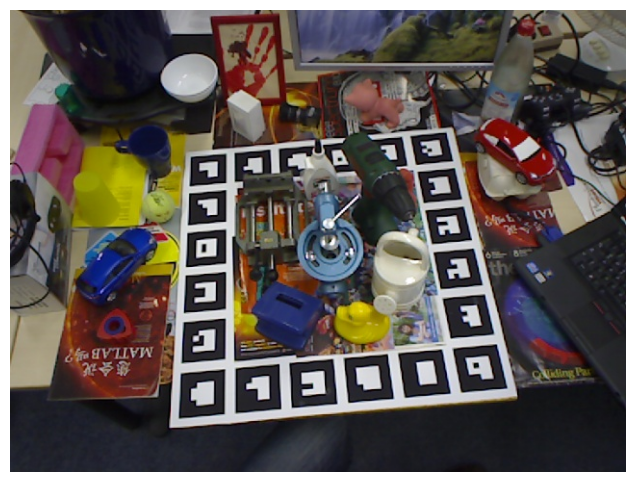

In [4]:
from remotezip import RemoteZip

BOP_URL = "https://huggingface.co/datasets/bop-benchmark/lmo/resolve/main"
SCENE_ID, IMAGE_ID = 2, 3
sample_files = {
    "lmo_test_bop19.zip": [f"test/{SCENE_ID:06d}/{name}" for name in (f"rgb/{IMAGE_ID:06d}.png", "scene_camera.json", "scene_gt.json")],
    "lmo_models.zip": ["models/models_info.json"],
}
DATA_DIR.mkdir(exist_ok=True)
for archive, members in sample_files.items():
    missing = [member for member in members if not (DATA_DIR / Path(member).name).exists()]
    if missing:
        with RemoteZip(f"{BOP_URL}/{archive}") as zip_file:
            for member in missing:
                (DATA_DIR / Path(member).name).write_bytes(zip_file.read(member))

image = cv2.imread(str(DATA_DIR / f"{IMAGE_ID:06d}.png"))
cam_K = np.array(json.loads((DATA_DIR / "scene_camera.json").read_text())[str(IMAGE_ID)]["cam_K"], dtype=np.float32).reshape(3, 3)
gt_poses = json.loads((DATA_DIR / "scene_gt.json").read_text())[str(IMAGE_ID)]
models_info = json.loads((DATA_DIR / "models_info.json").read_text())
# Object bounding-box size in meters for each GDRN class
extents = {
    i: np.array([models_info[str(obj_id)][k] for k in ("size_x", "size_y", "size_z")], dtype=np.float32) / 1000 for i, obj_id in enumerate(LMO_OBJECT_IDS)
}

plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off");

## Load the PyTorch models
[back to top ⬆️](#Table-of-contents:)

Both networks are rebuilt in `gdrnpp_helper.py` with parameter names that match the released checkpoints, so the weights load with `strict=True`.

* **YOLOX-X** takes a 640×640 letterboxed image and predicts, for each of 8400 anchor points, a box, an objectness score and 8 class probabilities.
* **GDRN** takes a 256×256 crop around each detection. A ConvNeXt-B backbone and a geometry head predict 64×64 maps of the visible mask, the object-space XYZ coordinate of every pixel and its surface region. A small Patch-PnP head regresses rotation and translation from these maps. During post-processing, OpenCV PnP-RANSAC solves the pose from the dense 2D-3D correspondences, which is usually more precise; the regressed pose is the fallback.

In [5]:
yolox_model = gdrnpp.load_yolox(YOLOX_CHECKPOINT)
gdrn_model = gdrnpp.load_gdrn(GDRN_CHECKPOINT)

for name, model in (("YOLOX-X", yolox_model), ("GDRN", gdrn_model)):
    print(f"{name}: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

YOLOX-X: 99.0 M parameters
GDRN: 102.6 M parameters


### Run the PyTorch models
[back to top ⬆️](#Table-of-contents:)

This runs on CPU in FP32 and gives us a reference to validate the converted models against.

In [6]:
yolox_input, ratio = gdrnpp.yolox_preprocess(image)
with torch.no_grad():
    pt_detector_out = yolox_model(torch.from_numpy(yolox_input)).numpy()
detections = gdrnpp.yolox_postprocess(pt_detector_out, conf_thr=CONF_THRESHOLD)

rois, roi_meta = gdrnpp.prepare_rois(image=image, detections=detections, ratio=ratio, extents=extents)
with torch.no_grad():
    pt_pose_out = [out.numpy() for out in gdrn_model(*(torch.from_numpy(value) for value in rois.values()))]
pt_poses = gdrnpp.recover_poses(outputs=pt_pose_out, meta=roi_meta, cam_K=cam_K)

print(f"Detected {len(pt_poses)} objects:", ", ".join(LMO_OBJECT_NAMES[pose["class_id"]] for pose in pt_poses))

Detected 7 objects: holepuncher, duck, driller, can, cat, glue, eggbox


## Convert the models to OpenVINO IR
[back to top ⬆️](#Table-of-contents:)

OpenVINO supports PyTorch models via conversion to OpenVINO Intermediate Representation (IR). `ov.convert_model` traces the model with an example input and returns an `ov.Model`, which `ov.save_model` writes to disk with FP16-compressed weights.

Two optimizations are applied before saving:

* **Static input shapes.** Both models get fully static shapes, which NPU requires and which let every device resolve tensor sizes at compile time. GDRN processes a fixed batch of 8 ROIs; the pipeline below pads or splits the detections to fit.
* **Folded normalization constants.** In every ConvNeXt block, the LayerNorm scale and shift are merged into the weights of the following linear layer, and the layer-scale factor into the weights of the preceding one. This removes element-wise multiply and add operations from the graph without changing the result.

In [7]:
MODEL_DIR.mkdir(exist_ok=True)

if not YOLOX_IR_PATH.exists():
    example_input = torch.zeros(1, 3, 640, 640)
    ov_model = ov.convert_model(yolox_model, example_input=example_input, input=[tuple(example_input.shape)])
    ov.save_model(model=ov_model, output_model=YOLOX_IR_PATH)

if not GDRN_IR_PATH.exists():
    gdrnpp.fold_norm_affine(gdrn_model)
    example_input = (
        torch.zeros(GDRN_BATCH, 3, 256, 256),
        torch.zeros(GDRN_BATCH, dtype=torch.int64),
        torch.zeros(GDRN_BATCH, 2, 64, 64),
        torch.ones(GDRN_BATCH, 3),
    )
    ov_model = ov.convert_model(gdrn_model, example_input=example_input, input=[tuple(t.shape) for t in example_input])
    ov.save_model(model=ov_model, output_model=GDRN_IR_PATH)

for path in (YOLOX_IR_PATH, GDRN_IR_PATH):
    model = core.read_model(path)
    print(
        f"{path.name}: inputs {[f'{p.any_name}{p.shape}' for p in model.inputs]}, "
        f"{len(model.get_ordered_ops())} operations, FP16 weights {path.with_suffix('.bin').stat().st_size / 2**20:.0f} MB"
    )

yolox.xml: inputs ['x[1,3,640,640]'], 1175 operations, FP16 weights 189 MB
gdrn.xml: inputs ['image[8,3,256,256]', 'roi_classes[8]', 'roi_coord_2d[8,2,64,64]', 'roi_extents[8,3]'], 1257 operations, FP16 weights 196 MB


## Run OpenVINO inference
[back to top ⬆️](#Table-of-contents:)

### Select inference device
[back to top ⬆️](#Table-of-contents:)

Select a device from the dropdown list for running inference using OpenVINO, and the minimum detection confidence (objectness × class probability). Lowering the threshold recovers heavily occluded objects at the cost of more false positives.

In [8]:
from notebook_utils import device_widget

device = device_widget()
conf_threshold = widgets.FloatSlider(value=CONF_THRESHOLD, min=0.01, max=0.95, step=0.01, description="Confidence:")

widgets.VBox([device, conf_threshold])

### Estimate object poses
[back to top ⬆️](#Table-of-contents:)

`PoseEstimator` chains the two compiled models with the NumPy/OpenCV pre- and post-processing and records how long each stage takes. Each pose is drawn as the object's 3D bounding box projected into the image. Re-run this cell after changing the device or the threshold.

7 poses on AUTO | detection: 857.9 ms | pose network: 1334.1 ms | PnP: 2.6 ms


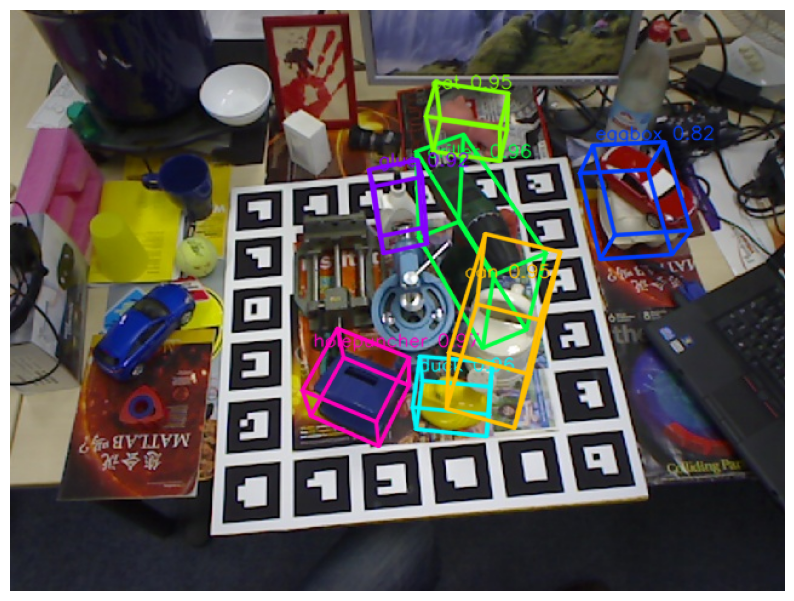

In [9]:
class PoseEstimator:
    def __init__(
        self,
        core: ov.Core,
        device_name: str,
        extents: dict,
        cam_K: np.ndarray,
        yolox_path: Path = YOLOX_IR_PATH,
        gdrn_path: Path = GDRN_IR_PATH,
        batch_size: int = GDRN_BATCH,
    ):
        """
        Compile both models and keep the camera and object information needed for pose recovery.

        :param core: OpenVINO runtime core
        :param device_name: inference device, for example "CPU", "GPU", "NPU" or "AUTO"
        :param extents: object bounding-box size in meters for each class
        :param cam_K: 3x3 camera intrinsic matrix
        :param yolox_path: path to the YOLOX IR
        :param gdrn_path: path to the GDRN IR
        :param batch_size: static ROI batch of the GDRN model
        """
        self.detector = core.compile_model(model=yolox_path, device_name=device_name)
        self.pose_net = core.compile_model(model=gdrn_path, device_name=device_name)
        self.extents = extents
        self.cam_K = cam_K
        self.batch_size = batch_size
        self.timings = {}

    def run_pose_net(self, rois: dict, start: int = 0) -> list:
        """
        Run GDRN on up to `batch_size` ROIs, zero-padding the static batch.

        :param rois: GDRN inputs for all ROIs
        :param start: index of the first ROI to process
        :returns: GDRN outputs for the processed ROIs
        """
        chunk = {name: value[start : start + self.batch_size] for name, value in rois.items()}
        n = len(chunk["image"])
        padded = {name: np.concatenate([value, np.zeros((self.batch_size - n, *value.shape[1:]), value.dtype)]) for name, value in chunk.items()}
        result = self.pose_net(padded)
        return [result[i][:n] for i in range(len(self.pose_net.outputs))]

    def __call__(self, image: np.ndarray, conf_thr: float) -> list:
        """
        Estimate the 6D pose of every detected object.

        :param image: BGR image
        :param conf_thr: minimum detection confidence
        :returns: list of poses with rotation `R`, translation `t` in meters, class and score
        """
        t0 = time.perf_counter()
        x, ratio = gdrnpp.yolox_preprocess(image)
        detections = gdrnpp.yolox_postprocess(self.detector(x)[0], conf_thr=conf_thr)
        t1 = time.perf_counter()
        rois, meta = gdrnpp.prepare_rois(image=image, detections=detections, ratio=ratio, extents=self.extents)
        outputs = [self.run_pose_net(rois=rois, start=start) for start in range(0, len(meta), self.batch_size)]
        t2 = time.perf_counter()
        poses = gdrnpp.recover_poses(outputs=[np.concatenate(o) for o in zip(*outputs)], meta=meta, cam_K=self.cam_K) if meta else []
        self.timings = {"detection": t1 - t0, "pose network": t2 - t1, "PnP": time.perf_counter() - t2}
        return poses


estimator = PoseEstimator(core=core, device_name=device.value, extents=extents, cam_K=cam_K)
poses = estimator(image=image, conf_thr=conf_threshold.value)

print(f"{len(poses)} poses on {device.value} | " + " | ".join(f"{stage}: {seconds * 1000:.1f} ms" for stage, seconds in estimator.timings.items()))
plt.figure(figsize=(10, 8))
plt.imshow(gdrnpp.draw_poses(image=image, poses=poses, extents=extents, cam_K=cam_K, names=LMO_OBJECT_NAMES))
plt.axis("off");

### Verify the conversion
[back to top ⬆️](#Table-of-contents:)

First, the converted models receive exactly the same inputs as the PyTorch run above, and we compare the outputs with cosine similarity; values close to 1.0 mean the conversion is numerically faithful.

Then the OpenVINO poses are compared with the LM-O ground truth: rotation error in degrees and translation error in millimeters. Eggbox and glue are symmetric, so a rotation error near 180° can still be a correct pose.

In [10]:
def cosine(a: np.ndarray, b: np.ndarray) -> float:
    return float(np.dot(a.ravel(), b.ravel()) / (np.linalg.norm(a) * np.linalg.norm(b)))


n = min(len(roi_meta), GDRN_BATCH)
ov_detector_out = estimator.detector(yolox_input)[0]
ov_pose_out = estimator.run_pose_net(rois=rois)
comparisons = {"YOLOX detections": (pt_detector_out, ov_detector_out)}
for i, name in enumerate(("rotation", "translation", "X coordinates", "Y coordinates", "Z coordinates", "visible mask")):
    comparisons[f"GDRN {name}"] = (pt_pose_out[i][:n], ov_pose_out[i])

print(f"{'output':<24}{'cosine':>10}")
for name, (reference, converted) in comparisons.items():
    print(f"{name:<24}{cosine(a=reference, b=converted):>10.6f}")

gt_by_class = {LMO_OBJECT_IDS.index(gt["obj_id"]): gt for gt in gt_poses}
print(f"\n{'object':<12}{'score':>7}{'method':>12}{'rot. err (deg)':>16}{'trans. err (mm)':>17}")
for pose in sorted(poses, key=lambda p: -p["score"]):
    gt = gt_by_class[pose["class_id"]]
    rot_err = gdrnpp.rotation_error_deg(r1=pose["R"], r2=np.reshape(gt["cam_R_m2c"], (3, 3)))
    trans_err = np.linalg.norm(pose["t"] * 1000 - np.array(gt["cam_t_m2c"]))
    print(f"{LMO_OBJECT_NAMES[pose['class_id']]:<12}{pose['score']:>7.2f}{pose['method']:>12}{rot_err:>16.1f}{trans_err:>17.1f}")

output                      cosine
YOLOX detections          1.000000
GDRN rotation             1.000000
GDRN translation          1.000000
GDRN X coordinates        1.000000
GDRN Y coordinates        1.000000
GDRN Z coordinates        1.000000
GDRN visible mask         0.999993

object        score      method  rot. err (deg)  trans. err (mm)
holepuncher    0.97  pnp_ransac             6.5             30.9
duck           0.96  pnp_ransac             6.7             15.8
driller        0.96  pnp_ransac             0.0              6.9
can            0.95  pnp_ransac             2.7              1.6
cat            0.95  pnp_ransac             6.2             18.7
glue           0.92  pnp_ransac             2.5             58.5
eggbox         0.82  pnp_ransac             6.9            152.6


## Clean up
[back to top ⬆️](#Table-of-contents:)

The checkpoints, converted models and compiled-model cache take about 1.5 GB in the `model` directory. Uncomment and run the cell below to delete them and the sample data.

In [11]:
# import shutil

# shutil.rmtree(MODEL_DIR, ignore_errors=True)
# shutil.rmtree(DATA_DIR, ignore_errors=True)